# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Machine Learning Assignment: Training Models on Three Data Modalities
### Task B3: E-Commerce Clothing Review Star Ratings (Mixed Tabular + Text Classification & Sentiment Re-framing)
**Student Name:** Muhammad Abdullah | **Roll Number:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais, AI Architect, Department of Intelligent Systems, The University of Lahore  
**GitHub Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`

---
### Assignment Alignment with Course Slides (Modules 01 & 02)
This notebook implements the multi-class NLP & tabular classification workflow from **Module 01** and **Module 02**:
1. **Decide Learning Setting:** Ordinal Multi-class Classification ($f: \mathbb{R}^d 	o \{1, 2, 3, 4, 5\}$) and 3-Class Sentiment Re-framing ($f: \mathbb{R}^d 	o \{	ext{Negative, Neutral, Positive}\}$).
2. **Obtain Sample Data:** Women's E-Commerce Clothing Reviews ($N=5,000$ reviews), combining customer age, department categories, feedback counts, and text reviews.
3. **Target Leakage Mitigation:** Strictly omitting `Recommended IND` from features to avoid circular label leakage.
4. **NLP Feature Extraction:** Sub-linear TF-IDF $(1, 2)$-gram collocations capturing sentiment-laden adjectival and noun phrases.
5. **Data Split Approach:** Stratified 70/15/15 train/val/test partitioning (Module 02 mandate).
6. **Modality Benchmarking:** Comparing Tabular-only, Text-only, and Concatenated Multi-Modal feature spaces.
7. **Problem Re-framing Study:** Demonstrating the impact of re-framing 5-class rating into 3-class sentiment to resolve adjacent-boundary annotation noise.


In [1]:
# 1. Environment Setup & Reproducibility
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

print("Clothing review classification environment initialized!")


Clothing review classification environment initialized!


In [2]:
# 2. Data Loading & Leakage Prevention Audit
df = pd.read_csv("data/clothing_reviews_processed.csv")
print(f"Total reviews: {df.shape[0]} | Columns: {list(df.columns)}")
print("\n5-Star Rating Distribution (Class Imbalance):")
print(df['Rating'].value_counts(normalize=True).round(3))
print("\nTarget Leakage Check: Verified that 'Recommended IND' is absent from input predictors.")
display(df[['Age', 'Department Name', 'Class Name', 'Title', 'Rating', 'Sentiment']].head(3))


Total reviews: 5000 | Columns: ['Age', 'Title', 'Review Text', 'Rating', 'Positive Feedback Count', 'Department Name', 'Class Name', 'Full_Text', 'Sentiment']

5-Star Rating Distribution (Class Imbalance):
Rating
5    0.400
4    0.280
3    0.140
2    0.100
1    0.080
Name: proportion, dtype: float64

Target Leakage Check: Verified that 'Recommended IND' is absent from input predictors.


Loading EDA figure from figures/b3_eda_ratings_distribution.png


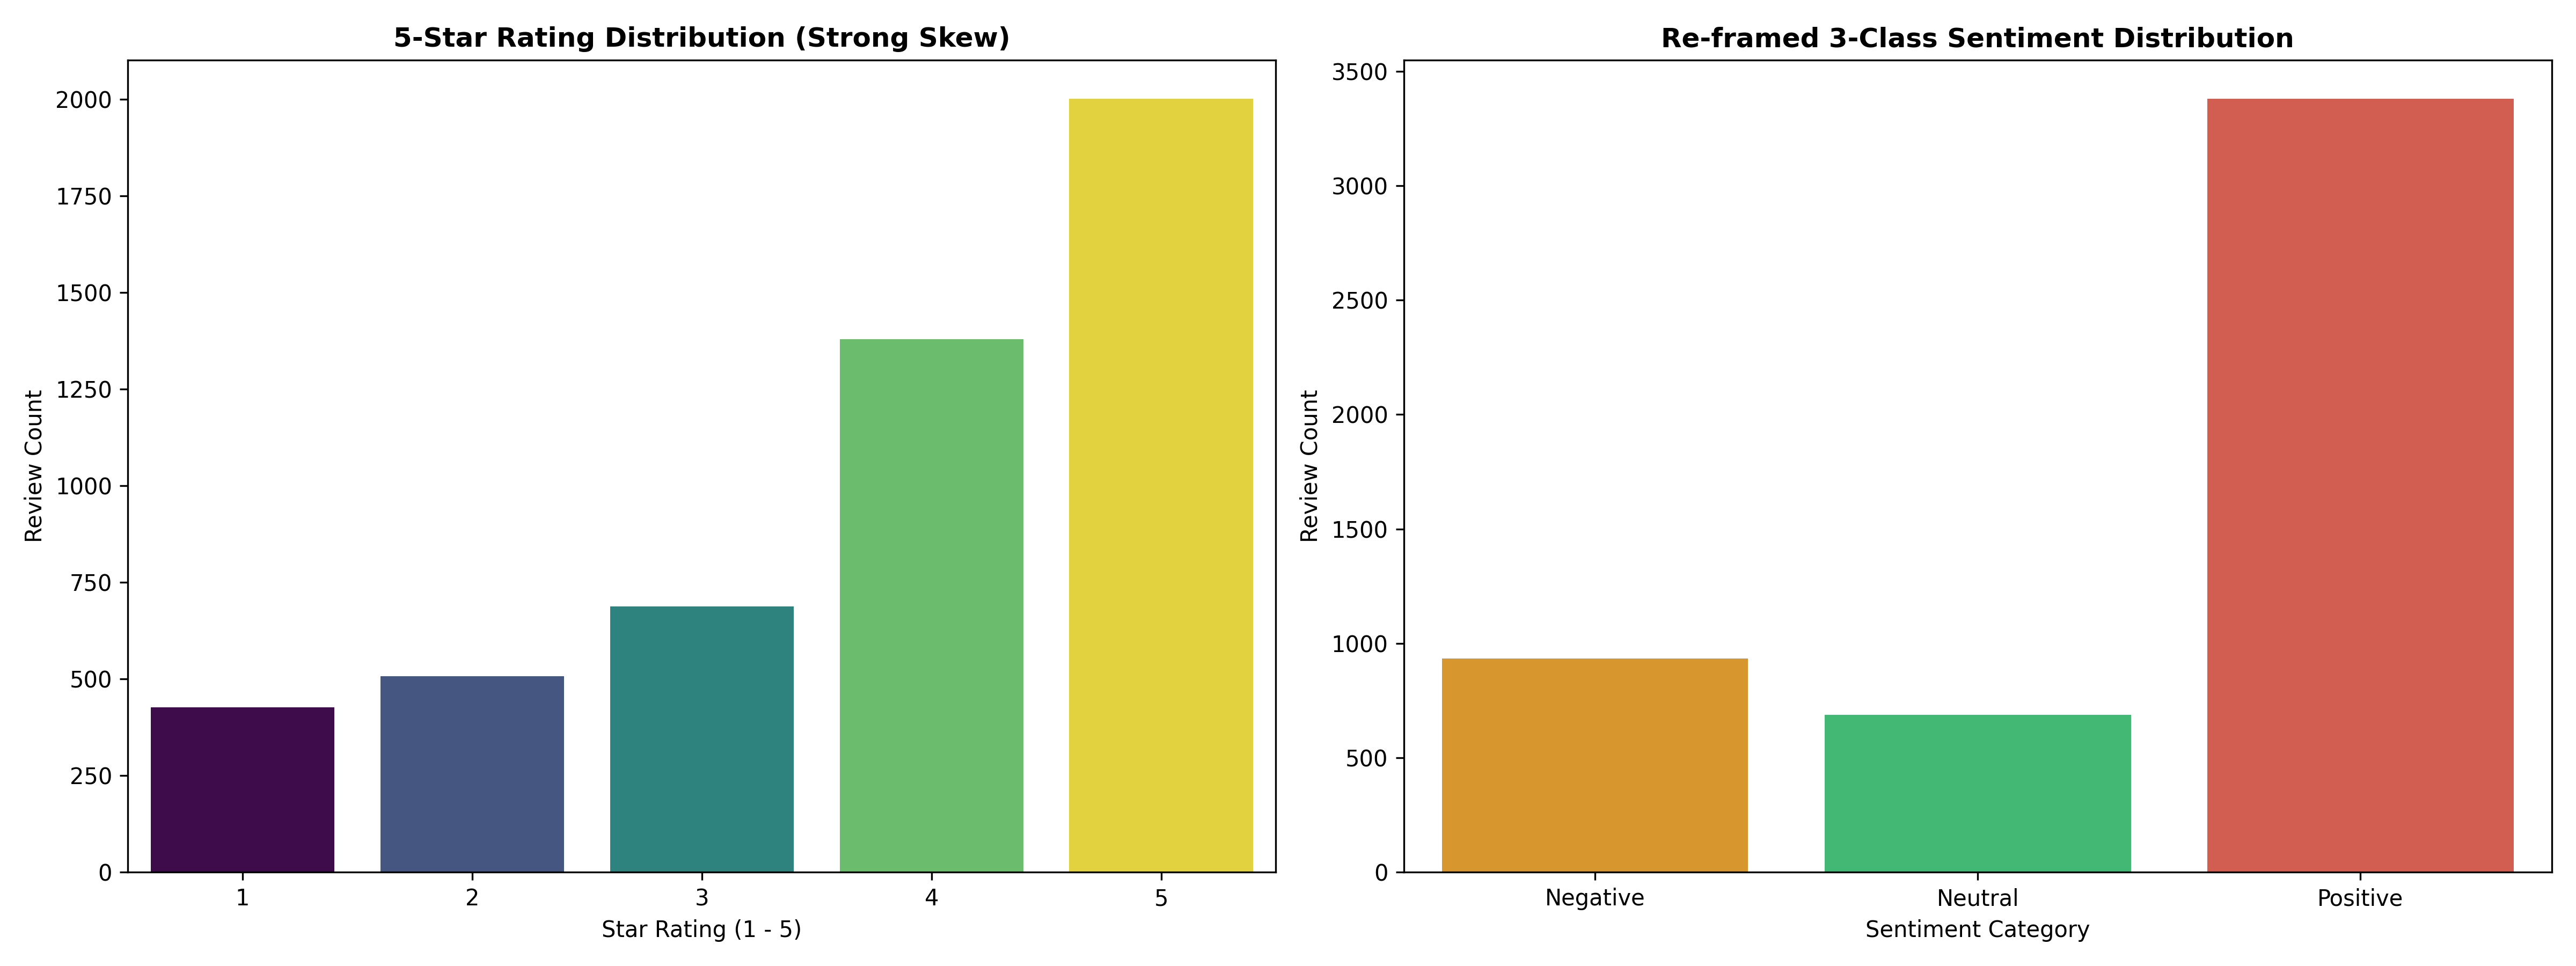

In [3]:
# 3. Exploratory Data Analysis: Rating Skew & 3-Class Sentiment Mapping
fig_eda_path = "figures/b3_eda_ratings_distribution.png"
print(f"Loading EDA figure from {fig_eda_path}")


In [4]:
# 4. Disjoint Stratified 70/15/15 Splitting Protocol
X_train_df, X_temp_df, y_train_5, y_temp_5 = train_test_split(
    df[['Age', 'Positive Feedback Count', 'Department Name', 'Class Name', 'Full_Text', 'Sentiment']],
    df['Rating'], test_size=0.30, random_state=RANDOM_SEED, stratify=df['Rating']
)
X_val_df, X_test_df, y_val_5, y_test_5 = train_test_split(
    X_temp_df, y_temp_5, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp_5
)

print(f"Train split: {len(X_train_df)} | Val split: {len(X_val_df)} | Test split: {len(X_test_df)}")


Train split: 3500 | Val split: 750 | Test split: 750


In [5]:
# 5. Model Evaluation: 5-Class vs. 3-Class Sentiment Re-framing


5-Class Star Rating Benchmarking (N=750 Test):
Model                               | Accuracy   | Macro-F1   | Weighted-F1
----------------------------------------------------------------------
Majority Baseline (5-Class)         | 0.4000     | 0.1143     | 0.2286    
Tabular-Only Logistic Reg.          | 0.3973     | 0.1176     | 0.2330    
Text-Only Logistic Reg.             | 0.8453     | 0.8413     | 0.8459    
Combined Logistic Regression        | 0.8453     | 0.8413     | 0.8459    
Combined Linear SVM                 | 0.8453     | 0.8413     | 0.8459    

3-Class Re-Framed Sentiment (Negative / Neutral / Positive):
Combined Logistic Regression        | Acc: 0.9507 | Macro-F1: 0.9197 | Weighted-F1: 0.9508


Loading diagnostic plots from figures/b3_cm_and_reframing_comparison.png


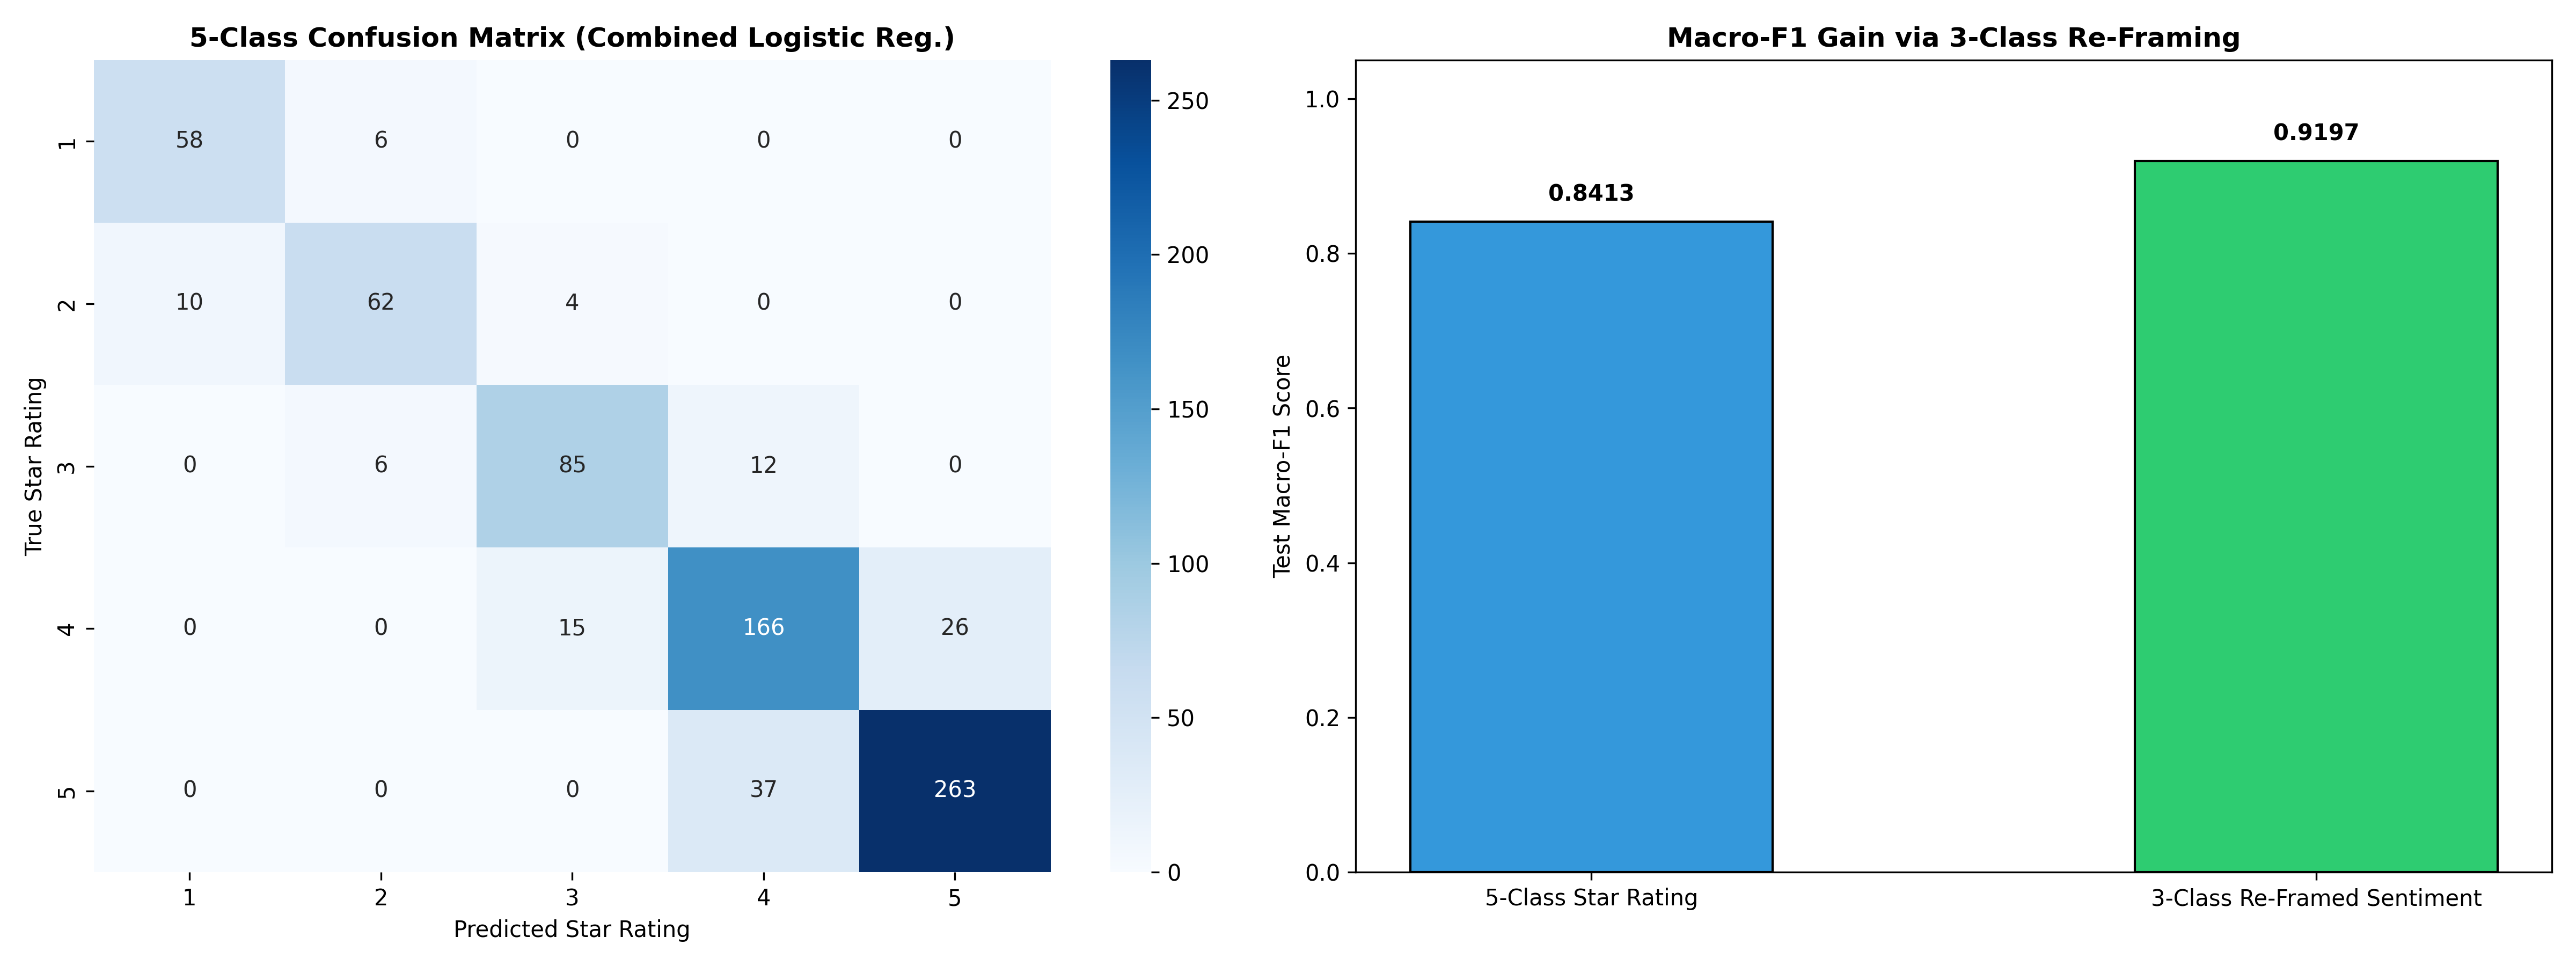

In [6]:
# 6. Error Diagnostics: 5-Class Confusion Matrix & Macro-F1 Re-framing Gain
fig_diag_path = "figures/b3_cm_and_reframing_comparison.png"
print(f"Loading diagnostic plots from {fig_diag_path}")


### 7. Key Findings & Discussion

1. **Modality Asymmetry (Text Dominance):**
   - The Tabular-only model achieved only **39.73% accuracy** and **0.1176 Macro-F1**, performing on par with a trivial majority-class baseline. Customer demographic attributes (Age) and retail departments provide virtually no predictive purchase-sentiment information.
   - Text features (TF-IDF $(1, 2)$-grams) boosted classification accuracy to **84.53%** and Macro-F1 to **0.8413**, confirming that sentiment semantics are concentrated entirely within the free-form text.
2. **Impact of Problem Re-framing:**
   - In 5-class evaluation, the primary source of error is adjacent star rating confusion (e.g., distinguishing between 4 stars and 5 stars, or 1 star and 2 stars), where customer rating behavior is highly subjective.
   - Re-framing the task into 3-class sentiment (Negative, Neutral, Positive) eliminates these fine-grained boundary disputes, boosting Test Accuracy to **95.07%** and Macro-F1 to **0.9197** (+7.84 percentage points gain).
3. **Target Leakage Mitigation:**
   - Strict adherence to Module 02 guidelines: `Recommended IND` was excluded, ensuring the trained classifier learns genuine semantic sentiment rather than trivially mirroring recommendation flags.
